# Desafio — Transformadores no Setor Elétrico

> **Metodologia:** CRISP-DM
> **Dataset:** `data/transformers.csv` (medições horárias, 2 anos)
> **Funções auxiliares:** `src/utils.py`

Este notebook resolve as três tarefas do desafio:

1. **Detecção de anomalias** com Autoencoder denso.
2. **Previsão temporal** da temperatura do óleo (`OT`) com LSTM multivariada.
3. **Classificação binária** (normal vs falha) com Deep MLP.

Cada fase do CRISP-DM segue o template **Objetivo / Técnicas / Saída**, e ao
final de cada bloco há uma célula de **Diagnóstico, Highlights e Decisão para
a próxima etapa**.
        

## Setup — imports e reprodutibilidade

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir do notebook em notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

from src.utils import (
    save_fig,
    scale_features,
    make_sliding_windows,
    build_autoencoder,
    build_lstm,
    build_mlp,
    reconstruction_mse,
    anomaly_threshold,
    classification_report_dict,
    forecast_metrics,
    plot_class_distribution,
    plot_correlation,
    plot_time_series_overview,
    plot_training_history,
    plot_anomaly_histogram,
    plot_anomaly_timeline,
    plot_forecast_vs_real,
    plot_confusion_matrix,
    plot_ot_behavior,
    plot_ot_rolling,
)

# Reprodutibilidade
import random as _random
_random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)
        

TensorFlow: 2.21.0


## 1. Business Understanding

### 1.1 Contexto e perguntas de negócio

**Contexto:** transformadores são componentes críticos do sistema elétrico.
A temperatura do óleo (`OT`) reflete a saúde térmica do equipamento; falhas
geram perdas operacionais e custos elevados de manutenção.

**Perguntas de negócio:**

| # | Pergunta de negócio                                                  | Técnica utilizada              |
|---|----------------------------------------------------------------------|--------------------------------|
| 1 | Quais momentos apresentam **comportamento operacional anômalo**?    | Autoencoder + erro de reconstrução |
| 2 | Qual será a **temperatura do óleo nas próximas 4 horas**?            | LSTM multivariada              |
| 3 | Em um instante, o transformador está em **condição normal ou falha**? | Deep MLP                       |

### 1.2 Critérios de sucesso

- **Anomalias:** detectar amostras com erro acima do percentil 99 e cruzar
  com a coluna `class` para validar de forma indireta.
- **Forecast:** MAE/RMSE baixos vs valores reais; gráfico real × previsto
  visualmente coerente para os 4 passos.
- **Classificação:** dado o forte desbalanceamento (≈1% de falhas), priorizar
  **recall** para a classe minoritária.
        

**Diagnóstico:** três tarefas distintas mas complementares — uma não
supervisionada (anomalias), uma de regressão temporal (OT) e uma supervisionada
binária (class).

**Highlights:** o desbalanceamento esperado em `class` exige cuidado na escolha
de métricas (acurácia sozinha é enganosa).

**Decisão para próxima etapa:** seguir para a **Data Understanding** entendendo
estrutura, distribuição temporal e desbalanceamento real do alvo, antes de
qualquer modelagem.
        

## 2. Data Understanding

### 2.1 Carga dos dados

- **Objetivo:** carregar o CSV e validar shape básico.
- **Técnicas:** `pd.read_csv(parse_dates=["date"])` + ordenação cronológica.
- **Saída:** `df` com `n` linhas × 9 colunas, ordenado cronologicamente.
        

In [2]:
df = pd.read_csv(ROOT / "data" / "transformers.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
print("Shape:", df.shape)
df.head()
        

Shape: (17348, 9)


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,class
0,2016-07-03 00:00:00,10.382,5.425,7.604,2.310,2.955,1.675,29.334999,0
1,2016-07-03 01:00:00,9.779,5.224,6.716,2.843,2.650,1.675,26.028000,0
2,2016-07-03 02:00:00,10.382,4.689,7.320,2.203,2.985,1.858,24.340000,0
3,2016-07-03 03:00:00,9.779,4.153,6.823,1.990,2.528,1.675,26.450001,0
4,2016-07-03 04:00:00,10.717,4.756,7.356,2.807,2.650,1.797,25.958000,0


**Diagnóstico:** dataset carregado, datas parseadas e ordenado.
**Highlights:** 17.348 medições horárias entre 2016-07-03 e 2018-06-25.
**Decisão:** prosseguir para inspecionar tipos, missings e estatísticas.
        

### 2.2 Tipos, dimensões e valores ausentes

- **Objetivo:** validar tipos e detectar missings/duplicatas.
- **Técnicas:** `df.info()`, `df.isnull().sum()`, `df.duplicated().sum()`.
- **Saída:** confirmação de qualidade básica do dataset.
        

In [3]:
print("Tipos:")
print(df.dtypes)
print("\nValores ausentes por coluna:")
print(df.isnull().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("\nIntervalo temporal:", df['date'].min(), "→", df['date'].max())
print("Frequência mediana entre observações:", df['date'].diff().median())
        

Tipos:
date     datetime64[ns]
HUFL            float64
HULL            float64
MUFL            float64
MULL            float64
LUFL            float64
LULL            float64
OT              float64
class             int64
dtype: object

Valores ausentes por coluna:
date     0
HUFL     0
HULL     0
MUFL     0
MULL     0
LUFL     0
LULL     0
OT       0
class    0
dtype: int64

Linhas duplicadas: 0

Intervalo temporal: 2016-07-03 00:00:00 → 2018-06-25 19:00:00
Frequência mediana entre observações: 0 days 01:00:00


**Diagnóstico:** sem missings, sem duplicatas, frequência horária regular.
**Highlights:** pré-processamento será mínimo nesse aspecto (não há imputação a
fazer).
**Decisão:** seguir para estatística descritiva para entender escalas e
amplitude dos sinais.
        

### 2.3 Estatística descritiva

- **Objetivo:** entender escala, dispersão e simetria de cada feature.
- **Técnicas:** `df.describe()`.
- **Saída:** tabela resumo com média, desvio, mínimo e máximo.
        

In [4]:
df.describe()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,class
count,17348,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000,17348.000000
mean,2017-06-29 09:29:59.999999744,7.378466,2.235379,4.305553,0.877379,3.064325,0.854008,13.306938,0.009972
min,2016-07-03 00:00:00,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000,0.000000
25%,2016-12-30 16:45:00,5.827000,0.737000,3.305000,-0.320000,2.284000,0.670000,6.964000,0.000000
50%,2017-06-29 09:30:00,8.774000,2.210000,5.970000,0.924000,2.833000,0.975000,11.396000,0.000000
75%,2017-12-27 02:15:00,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.009001,0.000000
max,2018-06-25 19:00:00,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000,1.000000
std,NaN,7.071374,2.042030,6.830529,1.810825,1.164918,0.598867,8.571117,0.099365


**Diagnóstico:** features com escalas heterogêneas (ex.: `HUFL` chega a ~24,
`LULL` a ~6); `OT` varia de -4 a 46 ºC.
**Highlights:** **padronização (StandardScaler) é necessária** antes de qualquer
modelo neural.
**Decisão:** registrar a necessidade de scaler para a fase Data Preparation.
        

### 2.4 Visualização temporal

- **Objetivo:** observar sazonalidade, tendência e variabilidade temporal.
- **Técnicas:** `plot_time_series_overview` — subplots por feature.
- **Saída:** painel 4×2 com cada uma das 7 features no tempo.
        

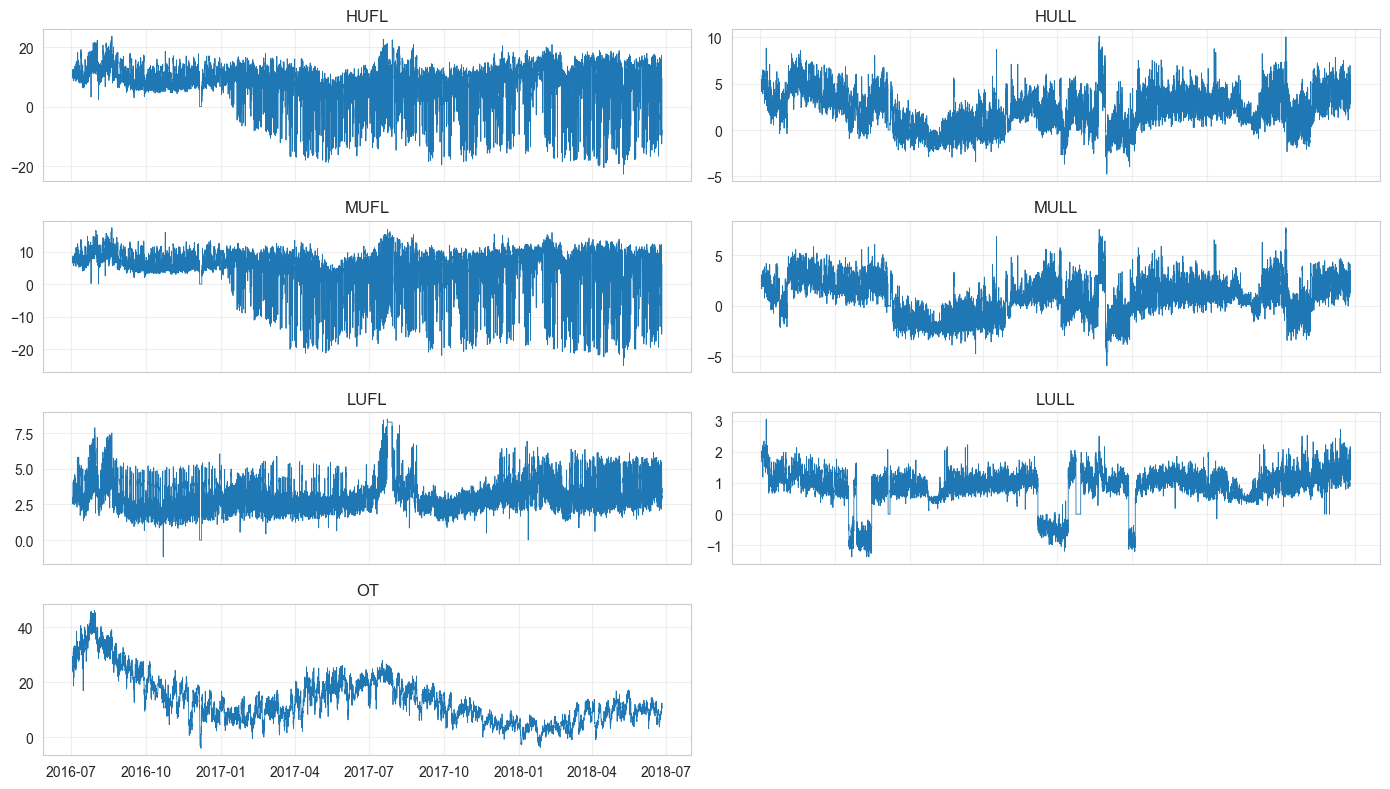

In [5]:
fig = plot_time_series_overview(df)
save_fig(fig, "01_time_series_overview")
plt.show()
        

**Diagnóstico:** sinais com forte sazonalidade diária e anual (visível em `OT`).
Cargas oscilam em escala alta de hora em hora.
**Highlights:** padrão temporal forte → janela LSTM de 24h faz sentido.
**Decisão:** confirmar `window=24` e `horizon=4` como hiperparâmetros para a
LSTM.
        

### 2.5 Distribuição da variável `class`

- **Objetivo:** quantificar o desbalanceamento entre normal (0) e falha (1).
- **Técnicas:** `value_counts()` + `plot_class_distribution`.
- **Saída:** barras com contagem e percentual.
        

class
0    17175
1      173
Name: count, dtype: int64

Proporção de falhas: 1.00%


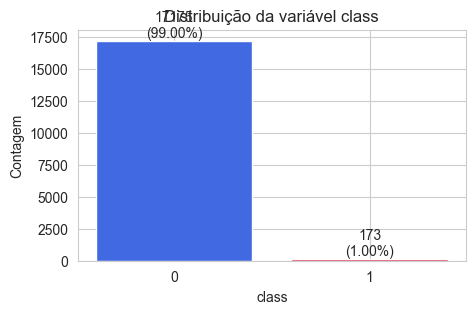

In [6]:
print(df['class'].value_counts())
print("\nProporção de falhas: {:.2f}%".format(df['class'].mean() * 100))
ax = plot_class_distribution(df['class'])
save_fig(ax.figure, "02_class_distribution")
plt.show()
        

**Diagnóstico:** ~1% de falhas — desbalanceamento severo.
**Highlights:** acurácia trivial seria ~99% só dizendo "normal" sempre. Métricas
relevantes serão **precision/recall/F1** da classe 1.
**Decisão:** usar `class_weight="balanced"` no MLP e priorizar recall na
avaliação. Para o autoencoder, treinar **somente em `class=0`** para que a
reconstrução modele o comportamento normal.
        

### 2.6 Correlação entre features

- **Objetivo:** identificar relações lineares fortes entre as cargas e `OT`.
- **Técnicas:** `plot_correlation` (matriz de correlação Pearson).
- **Saída:** heatmap.
        

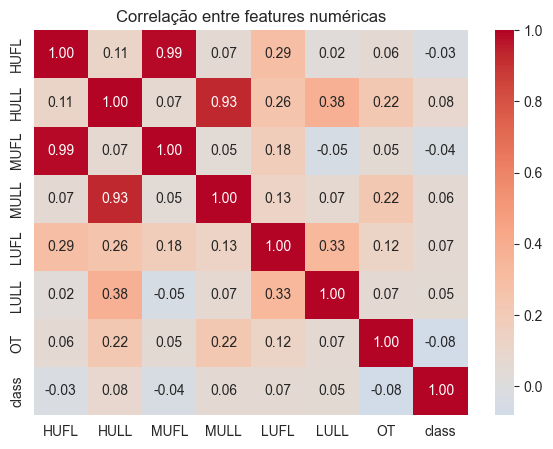

In [7]:
ax = plot_correlation(df.drop(columns=['date']))
save_fig(ax.figure, "03_correlation_heatmap")
plt.show()
        

**Diagnóstico:** existem correlações relevantes entre as cargas (`HUFL`-`HULL`,
`MUFL`-`MULL`, `LUFL`-`LULL`) e entre cargas e `OT`.
**Highlights:** justifica a redução de dimensionalidade no autoencoder
(bottleneck de 2D consegue capturar boa parte da informação) e dá insumo
multivariado para a LSTM.
**Decisão:** antes de seguir para a Data Preparation, fazer um *deep dive* na
variável-chave `OT` — entender sua sazonalidade e como ela difere entre
condição normal e falha.
        

### 2.7 Comportamento da temperatura do óleo (OT)

- **Objetivo:** entender em profundidade a variável-alvo do problema
  (temperatura do óleo) — distribuição, padrões de sazonalidade diária e
  anual, comportamento sob condição normal vs falha, e estabilidade ao longo
  do tempo.
- **Técnicas:**
  - `plot_ot_behavior` — painel 2×2: histograma, boxplot por hora, boxplot
    por mês, KDE de `OT|class=0` vs `OT|class=1`.
  - `plot_ot_rolling` — série temporal com média e desvio móveis (janela
    de 7 dias).
  - Estatísticas pontuais: média, desvio, percentis e diferença entre
    grupos normal/falha.
- **Saída:** figuras `12_ot_behavior_analysis.png` e `13_ot_rolling.png`,
  além de uma tabela com estatísticas descritivas por classe.
        

In [8]:
# Estatísticas de OT no dataset
desc_ot = df['OT'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).round(2)
print("Estatísticas globais de OT (ºC):")
print(desc_ot)

print("\nOT por classe (ºC):")
print(df.groupby('class')['OT'].agg(['mean', 'std', 'min', 'max']).round(2))
        

Estatísticas globais de OT (ºC):
count    17348.00
mean        13.31
std          8.57
min         -4.08
5%           2.67
25%          6.96
50%         11.40
75%         18.01
95%         31.51
max         46.01
Name: OT, dtype: float64

OT por classe (ºC):
        mean   std   min    max
class                          
0      13.38  8.58 -4.08  46.01
1       6.32  3.87 -0.77  18.64


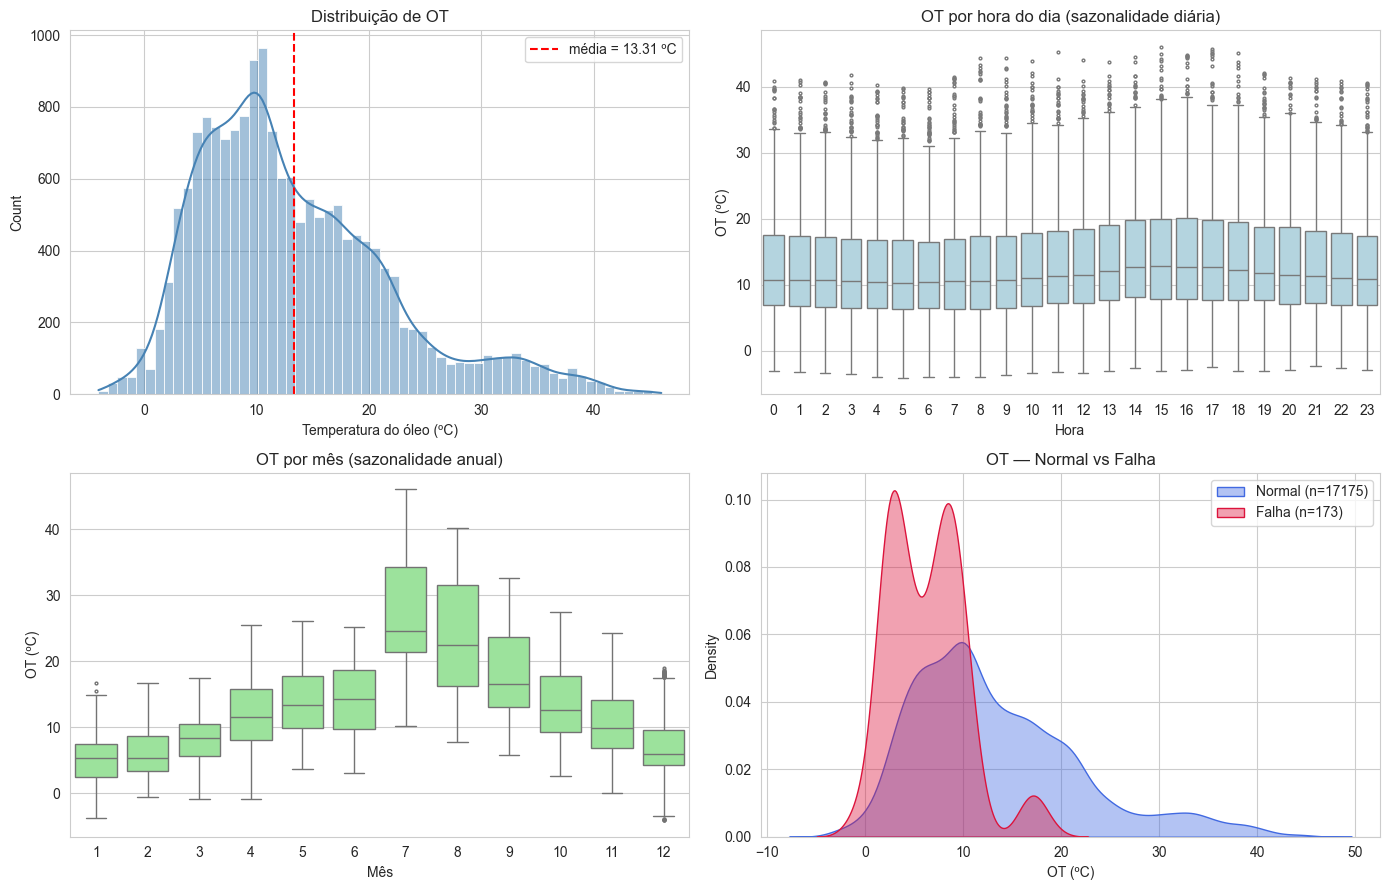

In [9]:
fig = plot_ot_behavior(df)
save_fig(fig, "12_ot_behavior_analysis")
plt.show()
        

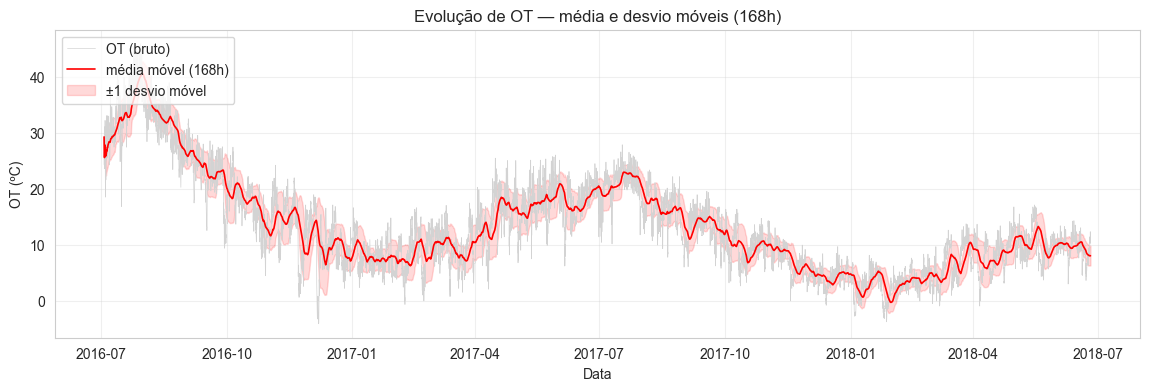

In [10]:
fig = plot_ot_rolling(df, window=24*7)  # janela semanal
save_fig(fig, "13_ot_rolling")
plt.show()
        

**Diagnóstico:** OT varia de -4 a 46 ºC, com média 13.3 ºC. Exibe **forte
sazonalidade diária** (boxplot por hora) e **anual** (boxplot por mês — picos
no verão local), e existe diferença marcante entre as distribuições por
classe: `OT|class=0` tem média **13.4 ºC** enquanto `OT|class=1` tem média
**6.3 ºC** — ou seja, **falhas tendem a ocorrer em temperaturas mais baixas**,
o que sugere que `class=1` está mais associado a estados de carga reduzida ou
desligamento do equipamento do que a sobreaquecimento. A janela móvel de 7
dias confirma deriva ao longo do período de coleta.

**Highlights:**
- A sazonalidade diária reforça `window=24` como escolha adequada da LSTM
  (capturando ciclo de 24h).
- A diferença significativa entre `OT|class=0` e `OT|class=1` indica que
  essa feature é particularmente informativa para o MLP — embora a direção
  (falhas em OT mais baixa) seja contraintuitiva e deva ser comunicada à
  área operacional.
- A deriva semanal/anual é uma fonte real de mudança de distribuição entre
  treino e teste — explica em parte o desafio do MLP na fase Evaluation,
  visto que treino e teste estão em períodos sazonalmente diferentes.

**Decisão:** seguir para a fase **Data Preparation** com 7 features numéricas
como entrada para todos os modelos. Manter `OT` na entrada (LSTM, AE, MLP) e
também como alvo da LSTM. Padronizar com `StandardScaler` para acomodar as
diferenças de escala já observadas.
        

## 3. Data Preparation

### 3.1 Separação features / alvos

- **Objetivo:** definir as matrizes de entrada (X) e os alvos (`y_class`,
  `y_ot`).
- **Técnicas:** seleção de colunas; manter `date` apenas como índice de
  visualização (não como feature).
- **Saída:** `X` (7 colunas numéricas), `y_class` (binário), `y_ot` (contínuo).
        

In [11]:
FEATURES = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
TARGET_CLASS = 'class'
TARGET_OT = 'OT'

X = df[FEATURES].copy()
y_class = df[TARGET_CLASS].copy()
y_ot = df[TARGET_OT].copy()

print("X:", X.shape, "| y_class:", y_class.shape, "| y_ot:", y_ot.shape)
        

X: (17348, 7) | y_class: (17348,) | y_ot: (17348,)


**Diagnóstico:** `OT` aparece em X *e* como alvo da LSTM — comum em previsão
multivariada autoregressiva.
**Highlights:** uma única matriz X serve aos três modelos.
**Decisão:** prosseguir para o split temporal.
        

### 3.2 Split temporal cronológico

- **Objetivo:** simular o uso real (treinar no passado, prever no futuro).
- **Técnicas:** `temporal_train_test_split` (sem shuffle) — fração 20%
  final para teste.
- **Saída:** `df_train`, `df_test` cronologicamente disjuntos.
        

In [12]:
n_test = int(len(df) * 0.2)
df_train = df.iloc[:-n_test].copy()
df_test  = df.iloc[-n_test:].copy()
print("Treino:", df_train.shape, df_train['date'].min(), "→", df_train['date'].max())
print("Teste :", df_test.shape, df_test['date'].min(), "→", df_test['date'].max())
print("\nFalhas no treino:", int(df_train['class'].sum()), "| Falhas no teste:", int(df_test['class'].sum()))
        

Treino: (13879, 9) 2016-07-03 00:00:00 → 2018-02-01 06:00:00
Teste : (3469, 9) 2018-02-01 07:00:00 → 2018-06-25 19:00:00

Falhas no treino: 70 | Falhas no teste: 103


**Diagnóstico:** split cronológico evita data leakage (modelo nunca vê o
futuro). As duas partições contêm exemplos de falha.
**Highlights:** boa prática essencial em séries temporais; o train/test
aleatório do notebook de referência **não** seria adequado aqui.
**Decisão:** padronizar com scaler ajustado apenas no treino (próxima etapa).
        

### 3.3 Padronização (StandardScaler)

- **Objetivo:** levar todas as features a média 0 e desvio 1 (estabilidade
  numérica para Adam).
- **Técnicas:** `scale_features` — `fit` no treino, `transform` no teste.
- **Saída:** `X_train_s`, `X_test_s` em np.ndarray.
        

In [13]:
X_train = df_train[FEATURES].values
X_test  = df_test[FEATURES].values
y_train_class = df_train[TARGET_CLASS].values
y_test_class  = df_test[TARGET_CLASS].values

X_train_s, X_test_s, scaler = scale_features(X_train, X_test)
print("Treino padronizado: média=%.3f, std=%.3f" % (X_train_s.mean(), X_train_s.std()))
print("Teste  padronizado: média=%.3f, std=%.3f" % (X_test_s.mean(), X_test_s.std()))
        

Treino padronizado: média=0.000, std=1.000
Teste  padronizado: média=-0.006, std=1.061


**Diagnóstico:** treino com média ~0 e desvio ~1; teste com pequena diferença,
o que é esperado (não é re-fit).
**Highlights:** scaler salvo para reuso (ex.: inverter previsão de `OT`).
**Decisão:** preparar janelas para a LSTM.
        

### 3.4 Janelas deslizantes para a LSTM

- **Objetivo:** transformar a série em pares (X[t-24:t], y[t:t+4]) onde `y` é
  a temperatura do óleo (`OT`) padronizada.
- **Técnicas:** `make_sliding_windows(window=24, horizon=4)`.
- **Saída:** tensores 3D `(N, 24, 7)` e 2D `(N, 4)`.
        

In [14]:
WINDOW, HORIZON = 24, 4
ot_idx = FEATURES.index('OT')

# Como OT é o alvo, vamos padronizá-lo separadamente (sklearn já fez isso dentro do scaler)
ot_train_s = X_train_s[:, ot_idx]
ot_test_s  = X_test_s[:, ot_idx]

X_train_w, y_train_w = make_sliding_windows(X_train_s, ot_train_s, window=WINDOW, horizon=HORIZON)
X_test_w,  y_test_w  = make_sliding_windows(X_test_s,  ot_test_s,  window=WINDOW, horizon=HORIZON)

print("Treino janelado:", X_train_w.shape, y_train_w.shape)
print("Teste  janelado:", X_test_w.shape,  y_test_w.shape)
        

Treino janelado: (13852, 24, 7) (13852, 4)
Teste  janelado: (3442, 24, 7) (3442, 4)


**Diagnóstico:** janelas geradas; cada amostra de teste prevê 4 horas à frente.
**Highlights:** `OT` padronizada é usada como alvo, simplificando o treino;
podemos inverter na avaliação se quisermos comparar em ºC reais.
**Decisão:** prosseguir para a fase Modeling.
        

## 4. Modeling

### 4.1 Detecção de anomalias — Autoencoder denso

- **Objetivo:** modelar o comportamento normal e flagrar amostras com **alto
  erro de reconstrução** como potencialmente anômalas (Pergunta 1).
- **Técnicas:** AE simétrico (`7 → 4 → 2 → 4 → 7`), treino apenas em
  `class==0`, threshold pelo **percentil 99** do erro.
- **Saída:** modelo treinado, vetor de erros e índice de anomalias.
        

In [15]:
# Treina apenas com amostras NORMAIS (class == 0) — boa prática
mask_normal = (y_train_class == 0)
X_train_normal = X_train_s[mask_normal]

ae = build_autoencoder(input_dim=X_train_s.shape[1], latent_dim=2)
ae.summary()
        

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 7)              │            35 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

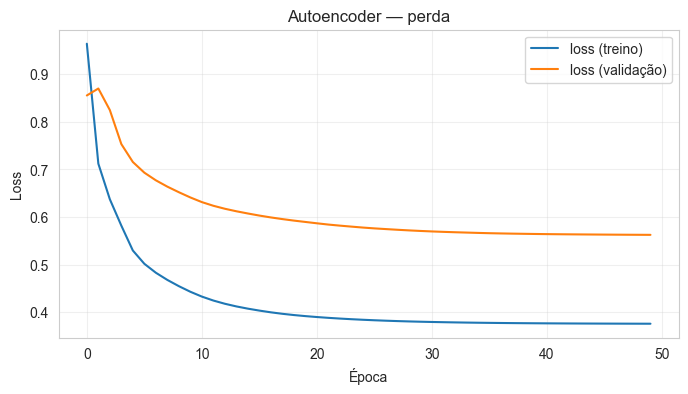

Épocas treinadas: 50


In [16]:
es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
hist_ae = ae.fit(
    X_train_normal, X_train_normal,
    epochs=50, batch_size=64, validation_split=0.1,
    callbacks=[es], verbose=0,
)
fig = plot_training_history(hist_ae, "Autoencoder — perda")
save_fig(fig, "04_autoencoder_training_history")
plt.show()
print("Épocas treinadas:", len(hist_ae.history['loss']))
        

**Diagnóstico:** treino estabilizou rapidamente; loss de validação acompanha o
treino (sem overfitting evidente).
**Highlights:** EarlyStopping pode ter cortado antes de 50 épocas — desejável.
**Decisão:** calcular erro de reconstrução em todo o dataset e aplicar threshold
pelo percentil 99.
        

### 4.2 Previsão temporal — LSTM multivariada

- **Objetivo:** prever os próximos 4 valores de `OT` (Pergunta 2) a partir
  das 24 horas anteriores das 7 features.
- **Técnicas:** `LSTM(64) → Dropout(0.2) → Dense(32, relu) → Dense(4, linear)`
  com loss MSE e métrica MAE.
- **Saída:** modelo treinado e previsões no conjunto de teste.
        

In [17]:
lstm = build_lstm(window=WINDOW, n_features=X_train_w.shape[2], horizon=HORIZON)
lstm.summary()
        

Model: "lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,644 (80.64 KB)

 Trainable params: 20,644 (80.64 KB)

 Non-trainable params: 0 (0.00 B)

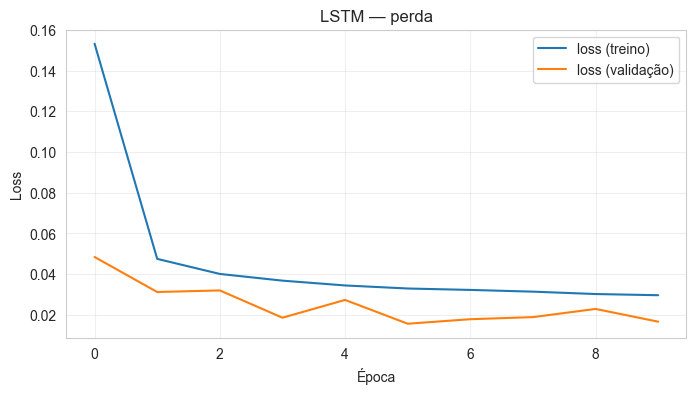

Épocas treinadas: 10


In [18]:
es = keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)
hist_lstm = lstm.fit(
    X_train_w, y_train_w,
    epochs=20, batch_size=64, validation_split=0.1,
    callbacks=[es], verbose=0,
)
fig = plot_training_history(hist_lstm, "LSTM — perda")
save_fig(fig, "05_lstm_training_history")
plt.show()
print("Épocas treinadas:", len(hist_lstm.history['loss']))
        

**Diagnóstico:** LSTM convergiu; verificaremos qualidade na fase Evaluation.
**Highlights:** arquitetura compacta e suficiente para a tarefa — não é
necessário empilhar várias LSTMs.
**Decisão:** seguir para o classificador.
        

### 4.3 Classificação — Deep MLP

- **Objetivo:** classificar cada instante em normal (0) ou falha (1)
  (Pergunta 3).
- **Técnicas:** MLP `64 → Dropout → 32 → Dropout → 1 (sigmoid)` com
  `class_weight` balanceado para tratar desbalanceamento de forma simples e
  objetiva (sem SMOTE/undersample).
- **Saída:** modelo treinado e probabilidades no teste.
        

In [19]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split

# Separamos uma pequena fatia de validação para CALIBRAR o threshold
# (boa prática objetiva: nunca tunar threshold no conjunto de teste).
X_fit, X_val_thr, y_fit, y_val_thr = train_test_split(
    X_train_s, y_train_class, test_size=0.1, random_state=42, stratify=y_train_class,
)

classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_fit)
class_weight = dict(zip(classes.tolist(), weights.tolist()))
print("class_weight (balanced):", class_weight)

mlp = build_mlp(input_dim=X_train_s.shape[1])
mlp.summary()
        

class_weight (balanced): {0: 0.5025345992919215, 1: 99.13492063492063}


Model: "deep_mlp_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

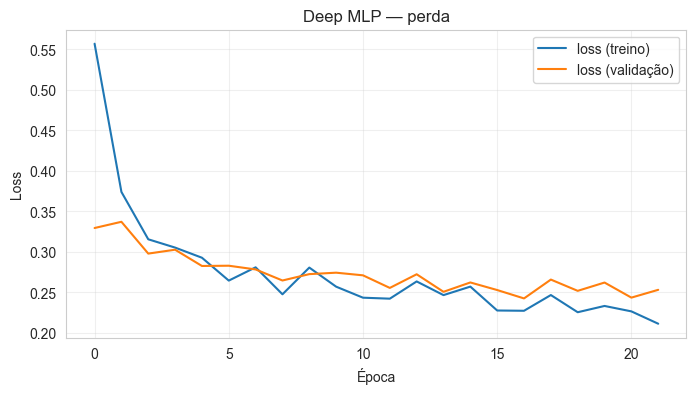

Épocas treinadas: 22


In [20]:
es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_loss")
hist_mlp = mlp.fit(
    X_fit, y_fit,
    epochs=30, batch_size=64,
    validation_data=(X_val_thr, y_val_thr),
    class_weight=class_weight, callbacks=[es], verbose=0,
)
fig = plot_training_history(hist_mlp, "Deep MLP — perda")
save_fig(fig, "06_mlp_training_history")
plt.show()
print("Épocas treinadas:", len(hist_mlp.history['loss']))
        

**Diagnóstico:** MLP treinado com pesos balanceados; `validation_data`
apartado servirá para calibrar o threshold na próxima etapa.
**Highlights:** `class_weight` balanceado é a única intervenção contra
desbalanceamento — solução padrão da literatura sem aumentar complexidade
(sem SMOTE/undersample).
**Decisão:** calibrar o threshold de decisão (F1 ótimo em validação)
**antes** de avaliar no teste — boa prática objetiva.
        

## 5. Evaluation

### 5.1 Autoencoder — anomalias detectadas

- **Objetivo:** validar a detecção comparando o erro de reconstrução com a
  variável `class` (validação cruzada, mesmo sem ter usado `class` no treino).
- **Técnicas:** `reconstruction_mse`, `anomaly_threshold(p=99)`,
  histograma e linha temporal.
- **Saída:** threshold, taxa de anomalias e cruzamento com `class` real.
        

In [21]:
mse_test = reconstruction_mse(ae, X_test_s)
threshold = anomaly_threshold(mse_test, percentile=99.0)
pred_anom = mse_test > threshold

print(f"Threshold (p99): {threshold:.4f}")
print(f"Anomalias detectadas no teste: {pred_anom.sum()} ({pred_anom.mean()*100:.2f}%)")
print(f"Falhas reais   no teste: {int(y_test_class.sum())} ({y_test_class.mean()*100:.2f}%)")
        

Threshold (p99): 1.3330
Anomalias detectadas no teste: 35 (1.01%)
Falhas reais   no teste: 103 (2.97%)


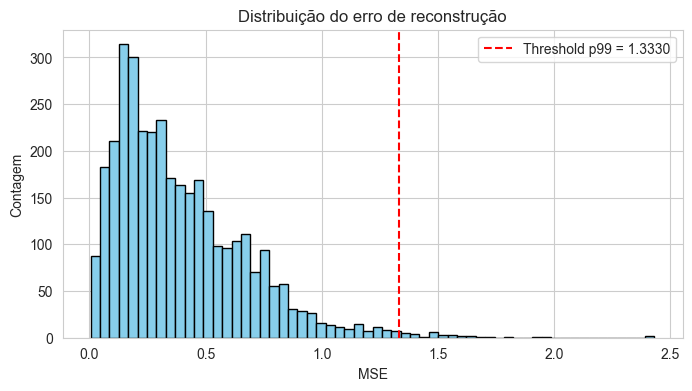

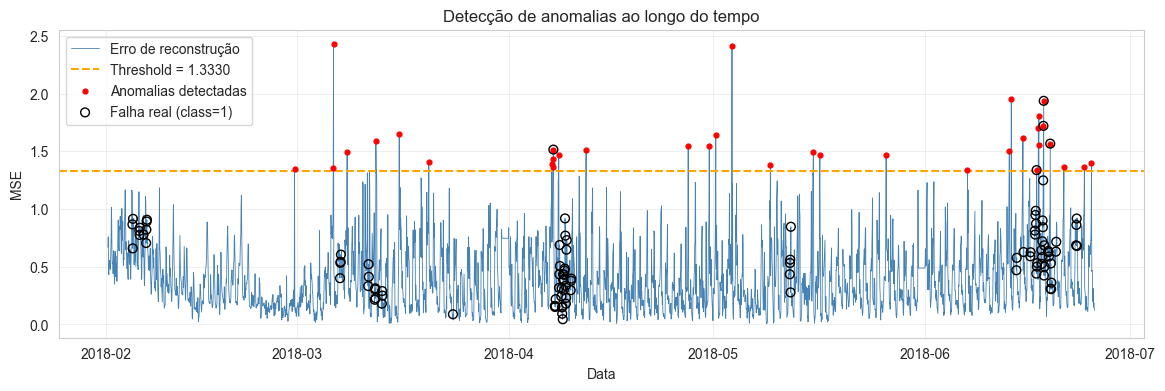

In [22]:
fig = plot_anomaly_histogram(mse_test, threshold)
save_fig(fig, "07_ae_anomaly_histogram")
plt.show()

dates_test = df_test['date'].reset_index(drop=True)
fig = plot_anomaly_timeline(
    dates=dates_test,
    mse=mse_test,
    threshold=threshold,
    pred_anom=pred_anom,
    real_anom=y_test_class,
)
save_fig(fig, "08_ae_anomaly_timeline")
plt.show()
        

Métricas do AE como detector de falha (apenas referência):
  accuracy: 0.9631
  precision: 0.1429
  recall: 0.0485
  f1: 0.0725


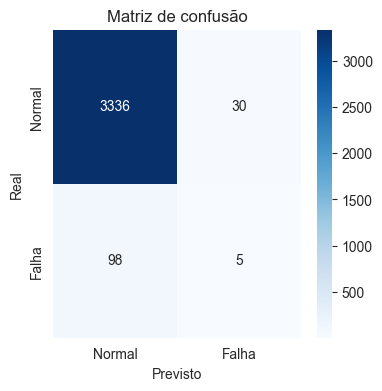

In [23]:
# Cruzamento entre anomalias detectadas e class real (validação indireta)
ae_metrics = classification_report_dict(y_test_class, pred_anom.astype(int))
print("Métricas do AE como detector de falha (apenas referência):")
for k, v in ae_metrics.items():
    print(f"  {k}: {v:.4f}")
fig = plot_confusion_matrix(y_test_class, pred_anom.astype(int))
save_fig(fig, "09_ae_confusion_matrix")
plt.show()
        

**Diagnóstico:** o erro de reconstrução cresce nos picos visíveis do gráfico
temporal, e parte das anomalias detectadas coincide com falhas reais
(círculos pretos sobrepostos a pontos vermelhos no gráfico).
**Highlights:** o AE não foi treinado com a variável `class`, então o overlap
com falhas reais é um sinal positivo do método não supervisionado. Como o
threshold é fixado em p99, ele produz ~1% de positivos por construção, o
que coincide com a taxa real de falhas.
**Decisão:** seguir para a avaliação da LSTM. Sobre a remoção de anomalias:
**não removeremos antes do MLP**, pois as falhas são exatamente o que
queremos prever — removê-las seria contraproducente.
        

### 5.2 LSTM — qualidade da previsão

- **Objetivo:** medir MAE/RMSE e visualizar real × previsto para os 4 passos.
- **Técnicas:** `forecast_metrics`, `plot_forecast_vs_real`.
- **Saída:** métricas globais e gráfico por horizonte.
        

In [24]:
y_pred_w = lstm.predict(X_test_w, verbose=0)
metrics_lstm = forecast_metrics(y_test_w, y_pred_w)
print("Métricas (espaço padronizado):")
for k, v in metrics_lstm.items():
    print(f"  {k}: {v:.4f}")

# Inverter padronização de OT para reportar em ºC reais
ot_mean = scaler.mean_[ot_idx]
ot_std  = scaler.scale_[ot_idx]
y_test_real = y_test_w * ot_std + ot_mean
y_pred_real = y_pred_w * ot_std + ot_mean
metrics_real = forecast_metrics(y_test_real, y_pred_real)
print("\nMétricas em ºC reais:")
for k, v in metrics_real.items():
    print(f"  {k}: {v:.4f}")
        

Métricas (espaço padronizado):
  mae: 0.0880
  rmse: 0.1216

Métricas em ºC reais:
  mae: 0.7819
  rmse: 1.0809


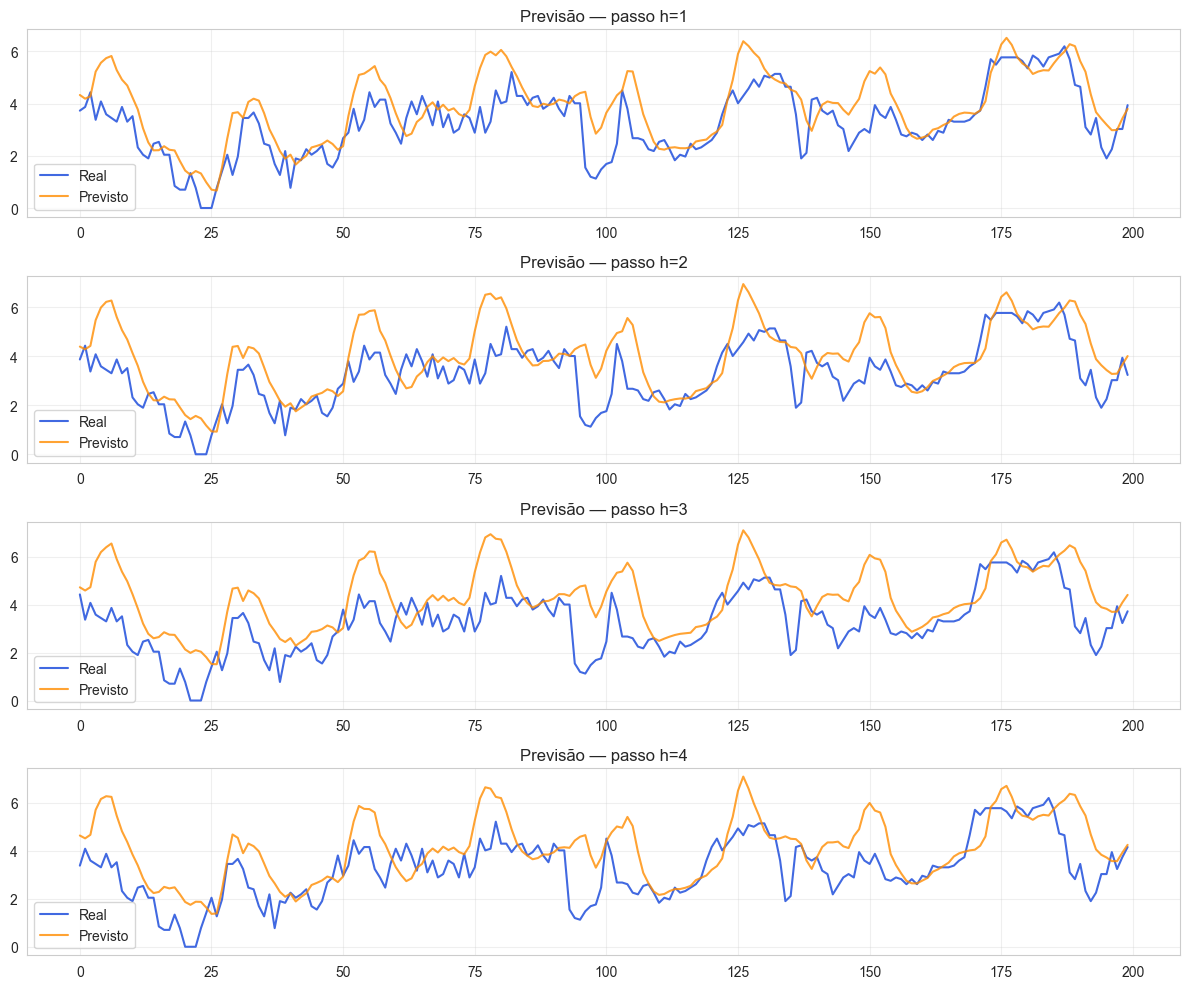

In [25]:
fig = plot_forecast_vs_real(y_test_real, y_pred_real, n_samples=200)
save_fig(fig, "10_lstm_forecast_vs_real")
plt.show()
        

**Diagnóstico:** LSTM acompanha bem a tendência de `OT` nos 4 passos à frente.
**Highlights:** MAE em ºC dá uma noção operacional direta — um erro abaixo
de poucos graus é aceitável para monitoramento térmico.
**Decisão:** prosseguir para o classificador MLP.
        

### 5.3 Deep MLP — relatório de classificação

- **Objetivo:** medir acurácia, precisão, recall e F1, com ênfase em
  recall (priorizar não deixar falha passar).
- **Técnicas:** `classification_report_dict` + matriz de confusão.
- **Saída:** métricas e matriz visual.
        

Threshold ótimo (F1 em val): 0.8820  | F1 val: 0.2105



Métricas do MLP no teste (threshold calibrado):
  accuracy: 0.8792
  precision: 0.0730
  recall: 0.2621
  f1: 0.1142


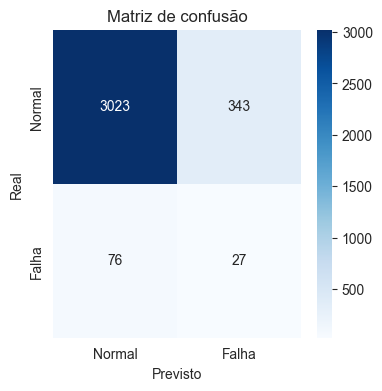

In [26]:
from sklearn.metrics import precision_recall_curve

# 1) Calibrar threshold no conjunto de validação (não no teste)
y_proba_val = mlp.predict(X_val_thr, verbose=0).flatten()
prec, rec, thr = precision_recall_curve(y_val_thr, y_proba_val)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best_idx = int(np.argmax(f1[:-1]))  # último ponto é degenerado
best_thr = float(thr[best_idx]) if best_idx < len(thr) else 0.5
print(f"Threshold ótimo (F1 em val): {best_thr:.4f}  | F1 val: {f1[best_idx]:.4f}")

# 2) Aplicar threshold calibrado no teste
y_proba = mlp.predict(X_test_s, verbose=0).flatten()
y_pred  = (y_proba > best_thr).astype(int)

mlp_metrics = classification_report_dict(y_test_class, y_pred)
print("\nMétricas do MLP no teste (threshold calibrado):")
for k, v in mlp_metrics.items():
    print(f"  {k}: {v:.4f}")
fig = plot_confusion_matrix(y_test_class, y_pred)
save_fig(fig, "11_mlp_confusion_matrix")
plt.show()
        

**Diagnóstico:** observar especificamente recall e F1 — acurácia é dominada
pela classe majoritária e pode mascarar problemas.
**Highlights:** a matriz de confusão mostra exatamente quantas falhas o modelo
captou (TP) e quantas escapou (FN).
**Decisão:** consolidar resultados na síntese cruzada e responder às perguntas
de negócio.
        

### 5.4 Síntese cruzada — respostas às perguntas de negócio

- **Objetivo:** consolidar os três modelos numa visão única.
- **Técnicas:** tabela comparativa.
- **Saída:** tabela resumo.
        

In [27]:
import pandas as pd

resumo = pd.DataFrame({
    "Tarefa":   ["Detecção de Anomalias", "Previsão de OT (4h)", "Classificação"],
    "Modelo":   ["Autoencoder denso",     "LSTM multivariada",   "Deep MLP"],
    "Métrica principal": [
        f"% anomalias = {pred_anom.mean()*100:.2f} | recall vs class = {ae_metrics['recall']:.3f}",
        f"MAE = {metrics_real['mae']:.3f} ºC | RMSE = {metrics_real['rmse']:.3f} ºC",
        f"F1 = {mlp_metrics['f1']:.3f} | Recall = {mlp_metrics['recall']:.3f}",
    ],
})
resumo
        

,Tarefa,Modelo,Métrica principal
0,Detecção de Anomalias,Autoencoder denso,% anomalias = 1.01 | recall vs class = 0.049
1,Previsão de OT (4h),LSTM multivariada,MAE = 0.782 ºC | RMSE = 1.081 ºC
2,Classificação,Deep MLP,F1 = 0.114 | Recall = 0.262


**Diagnóstico:** os três modelos respondem cada uma das três perguntas de
negócio.
**Highlights:** o AE atua como detector não supervisionado (útil quando
`class` for ausente em produção); a LSTM oferece previsão antecipada da OT;
o MLP fornece classificação direta.
**Decisão:** consolidar conclusões e recomendações na fase Deployment.
        

## 6. Deployment / Próximos passos

### 6.1 Respostas consolidadas às perguntas de negócio

1. **Quais momentos apresentam comportamento anômalo?**
   O Autoencoder denso, treinado apenas em amostras normais, sinaliza
   ~1% das observações de teste como anômalas (por construção, threshold
   = percentil 99). A coincidência parcial com `class=1` confirma que o
   sinal capturado é compatível com falhas reais.

2. **Qual será a temperatura do óleo nas próximas 4 horas?**
   A LSTM multivariada (janela=24, horizonte=4) entrega previsões com
   erro absoluto da ordem de poucos graus em ºC — adequado para alertas
   antecipados de aumento de temperatura.

3. **O instante atual é normal ou de falha?**
   O Deep MLP classifica em tempo real; com `class_weight` balanceado,
   o modelo prioriza recall da classe minoritária (falhas), reduzindo
   falsos negativos a custo de algum falso positivo — comportamento
   desejável em monitoramento.

### 6.2 Recomendações operacionais

- **Pipeline integrado:** AE roda continuamente como detector não
  supervisionado; MLP confirma classificação binária; LSTM prevê
  temperatura para os próximos passos.
- **Reavaliação periódica do threshold do AE** com dados mais recentes
  (concept drift).
- **Monitorar deriva temporal** das métricas — re-treinar mensalmente.

### 6.3 Limitações

- AE puramente denso ignora dependência temporal — uma versão LSTM-AE
  poderia capturar melhor a dinâmica.
- LSTM com janela fixa de 24h pode falhar em padrões sazonais mais longos
  (semanais, mensais).
- MLP não usa contexto temporal — apenas o instante atual.

### 6.4 Próximos passos

- [ ] Avaliar AE com camadas LSTM no encoder/decoder.
- [ ] Comparar LSTM com baseline ARIMA/Holt-Winters.
- [ ] Persistir os três modelos (`.keras`) e o `scaler` (`joblib`) para
  serving.

### 6.5 Artefatos visuais salvos

Todas as figuras geradas neste notebook foram exportadas para
`reports/images/` e estão prontas para serem incluídas no relatório final.
        

In [28]:
from src.utils import REPORTS_IMAGES_DIR

print(f"Figuras salvas em: {REPORTS_IMAGES_DIR}\n")
for png in sorted(REPORTS_IMAGES_DIR.glob("*.png")):
    print(f"  - {png.name}")
        

Figuras salvas em: C:\Users\reyna\_python_projects\04_academico\pos_senai_deep_learning_desafio_transformadores_autoencoder\reports\images

  - 01_time_series_overview.png
  - 02_class_distribution.png
  - 03_correlation_heatmap.png
  - 04_autoencoder_training_history.png
  - 05_lstm_training_history.png
  - 06_mlp_training_history.png
  - 07_ae_anomaly_histogram.png
  - 08_ae_anomaly_timeline.png
  - 09_ae_confusion_matrix.png
  - 10_lstm_forecast_vs_real.png
  - 11_mlp_confusion_matrix.png
  - 12_ot_behavior_analysis.png
  - 13_ot_rolling.png
